X_train: (240, 64, 64), y_train: (240,)
X_val:   (80, 64, 64), y_val:   (80,)
X_test:  (80, 64, 64), y_test:  (80,)
X_test_corrupted:  (80, 64, 64), y_test:  (80,)
Initial sample weights (w_1, not printing all values for clean logs):
[0.00416667 0.00416667 0.00416667 0.00416667 0.00416667]


LOGGING SAMME ONLY ROUND 0
Weak Learner Predictions h_1(x) (not printing all values for clean logs):
[0 0 0 0 0]
Ground Truth y (not printing all values for clean logs):
[33  0 17 20 37]
Misclassified Indicator (1[h_1(x) != y]) (not printing all values for clean logs):
[1 0 1 1 1]

Weighted Error (eps_1): 0.9500
Learner Weight (alpha_1):  0.7191

Updated & Normalized Sample Weights (w_2, not printing all values for clean logs):
[0.00427632 0.00208333 0.00427632 0.00427632 0.00427632]

Depth:1 | Rounds:10 | Train Acc:0.0500 | Val Acc:0.0375
Initial sample weights (w_1, not printing all values for clean logs):
[0.00416667 0.00416667 0.00416667 0.00416667 0.00416667]


LOGGING SAMME ONLY ROUND 0
Weak 

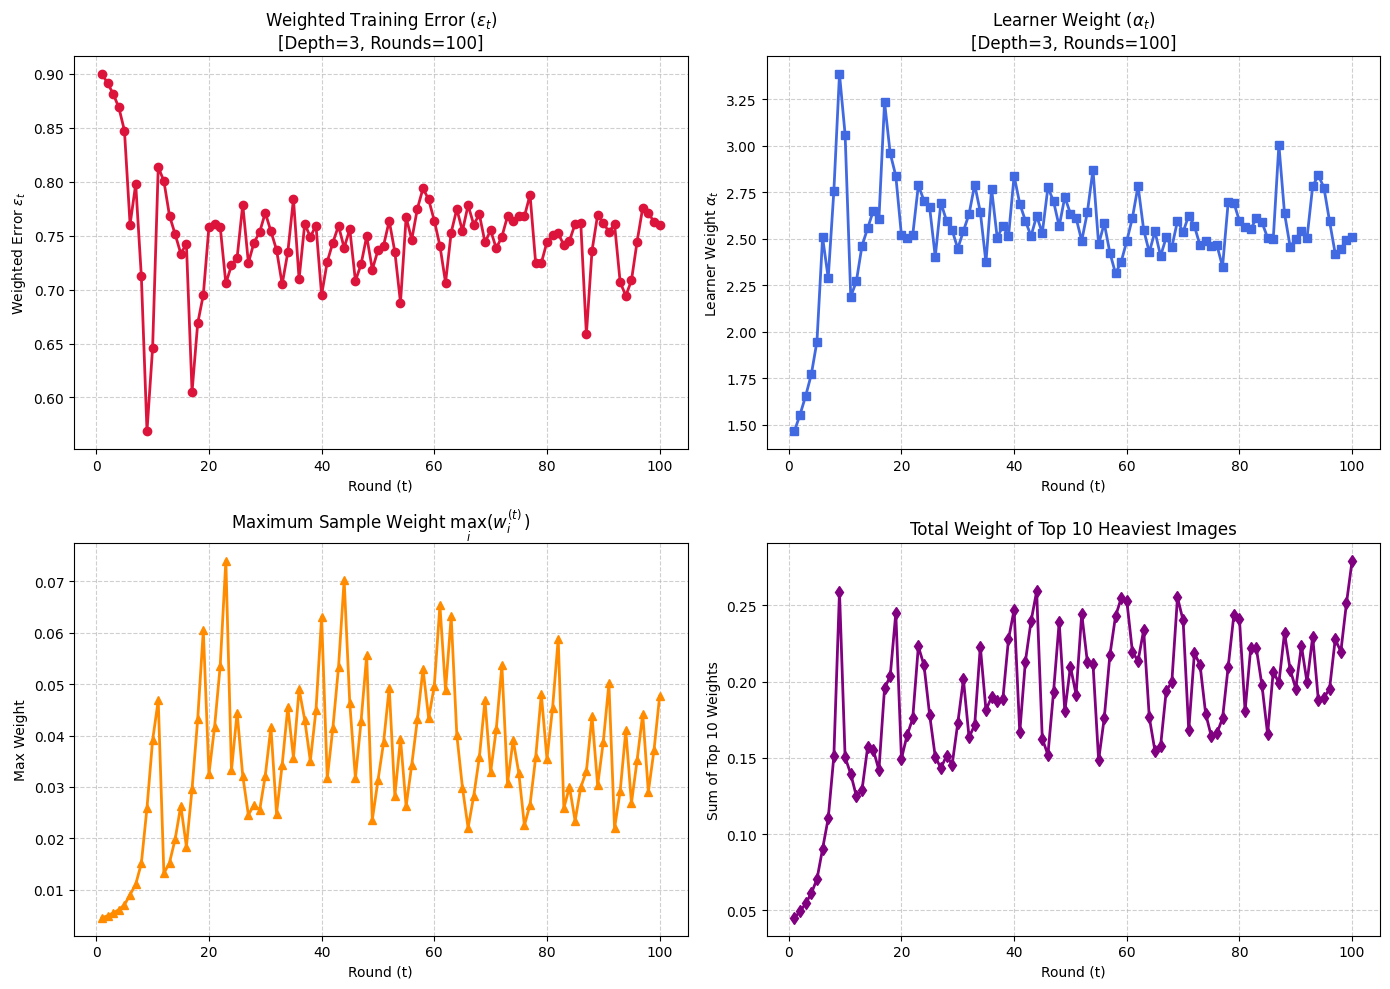

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q2_b.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

faces = fetch_olivetti_faces(shuffle=False)
X = faces.images
y = faces.target

height = X.shape[1]
width = X.shape[2]

split_data = np.load("olivetti_split_indices.npz")

train_idx = split_data["train"]
val_idx = split_data["val"]
test_idx = split_data["test"]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_test_corrupted = X_test.copy()
X_test_corrupted[:, 24:40, 24:40] = 0.0

logger.info(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
logger.info(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
logger.info(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
logger.info(f"X_test_corrupted:  {X_test_corrupted.shape}, y_test:  {y_test.shape}")




X_train = X_train.reshape(-1, height * width)
X_val = X_val.reshape(-1, height * width)
X_test = X_test.reshape(-1, height * width)
X_test_corrupted = X_test_corrupted.reshape(-1, height * width)

seed = 260007

def fit_samme_adaboost(X_flat, y, n_estimators, max_depth):

    N = len(y)
    classes = np.unique(y)
    K = len(classes)
    top_k = 10

    w = np.ones(N, dtype=np.float64) / N

    estimators = []
    estimator_weights = []

    history = {
        "eps_ts": [],
        "alphas": [],
        "max_sample_weights": [],
        "top10_weights": [],
        "sample_weights_over_time": []
    }

    logger.info("=" * 65)
    logger.info(f"Initial sample weights (w_1, not printing all values for clean logs):\n{w[:5]}\n")
    logger.info("=" * 65 + "\n")
    

    for t in range(n_estimators):
        clf = DecisionTreeClassifier(max_depth=max_depth, random_state=seed + t)
        clf.fit(X_flat, y, sample_weight=w)

        preds = clf.predict(X_flat)
        incorrect = (preds != y)

        eps_t = np.sum(w * incorrect) / np.sum(w)

        random_guess_error = 1.0 - (1.0 / K)
        if eps_t >= random_guess_error:
            if t == 0:
                alpha_t = 1e-10
                estimators.append(clf)
                estimator_weights.append(alpha_t)
            break

        if eps_t == 0:
            alpha_t = 100.0
        else:
            alpha_t = np.log((1.0 - eps_t) / eps_t) + np.log(K - 1)

        w_updated = w * np.exp(alpha_t * incorrect)

        w_next = w_updated / np.sum(w_updated)

        if t==0:
            logger.info(f"LOGGING SAMME ONLY ROUND {t}")
            logger.info(f"Weak Learner Predictions h_1(x) (not printing all values for clean logs):\n{preds[:5]}")
            logger.info(f"Ground Truth y (not printing all values for clean logs):\n{y[:5]}")
            logger.info(f"Misclassified Indicator (1[h_1(x) != y]) (not printing all values for clean logs):\n{incorrect.astype(int)[:5]}")
            logger.info(f"\nWeighted Error (eps_1): {eps_t:.4f}")
            logger.info(f"Learner Weight (alpha_1):  {alpha_t:.4f}")
            logger.info(f"\nUpdated & Normalized Sample Weights (w_2, not printing all values for clean logs):\n{w_next[:5]}")
            logger.info("=" * 65 + "\n")

        estimators.append(clf)
        estimator_weights.append(alpha_t)

        history["eps_ts"].append(eps_t)
        history["alphas"].append(alpha_t)
        history["max_sample_weights"].append(np.max(w_next))
        
        history["top10_weights"].append(np.sum(np.sort(w_next)[-top_k:]))
        history["sample_weights_over_time"].append(w_next.copy())

        w = w_next

    return estimators, estimator_weights, classes, history

def predict_samme(X_flat, estimators, estimator_weights, classes):
    N = len(X_flat)
    K = len(classes)
    scores = np.zeros((N, K))

    for clf, alpha in zip(estimators, estimator_weights):
        preds = clf.predict(X_flat)
        for k_idx, c in enumerate(classes):
            scores[:, k_idx] += alpha * (preds == c)

    best_indices = np.argmax(scores, axis=1)
    return classes[best_indices]

depths = [1, 2, 3, 4]
rounds_list = [10, 25, 50, 100]

results = []
best_val_acc = -1.0
best_config = None
best_model_data = None

for d in depths:
    for r in rounds_list:
        estimators, estimator_weights, classes, history = fit_samme_adaboost(
            X_flat=X_train,
            y=y_train,
            n_estimators=r,
            max_depth=d
        )
        
        train_preds = predict_samme(X_train, estimators, estimator_weights, classes)
        val_preds = predict_samme(X_val, estimators, estimator_weights, classes)

        train_acc = np.mean(train_preds == y_train)
        val_acc = np.mean(val_preds == y_val)

        results.append({
            "depth": d,
            "rounds": r,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "estimators": estimators,
            "estimator_weights": estimator_weights,
            "classes": classes,
            "history": history
        })

        logger.info(f"Depth:{d} | Rounds:{r} | Train Acc:{train_acc:.4f} | Val Acc:{val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_config = (d, r)
            best_model_data = (estimators, estimator_weights, classes, history)

logger.info("=" * 65)
logger.info(f"Selected Best Model: Depth = {best_config[0]}, Rounds = {best_config[1]} (Val Acc = {best_val_acc:.4f})")
logger.info("=" * 65)

_, _, _, best_history = best_model_data
rounds_range = np.arange(1, len(best_history["eps_ts"]) + 1)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.plot(rounds_range, best_history["eps_ts"], color="crimson", marker="o", linewidth=2)
plt.title(f"Weighted Training Error ($\\epsilon_t$)\n[Depth={best_config[0]}, Rounds={best_config[1]}]")
plt.xlabel("Round (t)")
plt.ylabel("Weighted Error $\\epsilon_t$")
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(2, 2, 2)
plt.plot(rounds_range, best_history["alphas"], color="royalblue", marker="s", linewidth=2)
plt.title(f"Learner Weight ($\\alpha_t$)\n[Depth={best_config[0]}, Rounds={best_config[1]}]")
plt.xlabel("Round (t)")
plt.ylabel("Learner Weight $\\alpha_t$")
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(2, 2, 3)
plt.plot(rounds_range, best_history["max_sample_weights"], color="darkorange", marker="^", linewidth=2)
plt.title("Maximum Sample Weight $\\max_i(w_i^{(t)})$")
plt.xlabel("Round (t)")
plt.ylabel("Max Weight")
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(2, 2, 4)
plt.plot(rounds_range, best_history["top10_weights"], color="purple", marker="d", linewidth=2)
plt.title("Total Weight of Top 10 Heaviest Images")
plt.xlabel("Round (t)")
plt.ylabel("Sum of Top 10 Weights")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

plt.savefig("q2_b_adaboost_metrics.png", dpi=300, bbox_inches="tight")

plt.show()